# # Binarna klasifikacija - Predviđanje statusa pušača
#
# Binarna klasifikacija znači da model svrstava primjere u jednu od dvije klase. Ovdje je cilj
# predvidjeti je li osoba pušač na temelju dobi, spola, BMI-a, broja djece i regije.
#
# Target `smoker` pretvaram iz `yes`/`no` u 1/0. Stupac `charges` se **ne koristi** kao
# značajka u osnovnoj klasifikaciji jer su troškovi posljedica pušenja, pa bi takav model
# praktički "vidio" odgovor kroz target iz regresijskog zadatka.
#
# Modeli: Logistic Regression, Random Forest i XGBoost, uz baseline (`DummyClassifier`) jer su
# klase neuravnotežene. Uz klasične modele treniraju se i dvije neuronske mreže različitih
# arhitektura i različitih funkcija gubitka.

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler
from tensorflow import keras
from xgboost import XGBClassifier

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "insurance.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "classification"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

NUMERIC_FEATURES = ["age", "bmi", "children"]
CATEGORICAL_FEATURES = ["sex", "region"]
TARGET_SOURCE = "smoker"
TEST_SIZE = 0.2
VALIDATION_SPLIT = 0.2
CLASS_LABELS = ["nepušač", "pušač"]

In [2]:
def save_and_show(figure, filename):
    """Sprema graf u outputs/classification i prikazuje ga inline."""
    figure.tight_layout()
    figure.savefig(OUTPUT_DIR / filename, dpi=120, bbox_inches="tight")
    plt.show()


def slugify(label):
    """Pretvara naziv modela u sigurno ime datoteke."""
    for character in " ()[]=.,+-":
        label = label.replace(character, "_")
    return label.strip("_").lower()


def build_preprocessor(scaler=None):
    """ColumnTransformer: one-hot za kategorijske, opcionalni scaler za numeričke varijable."""
    numeric_transformer = "passthrough" if scaler is None else scaler
    return ColumnTransformer(
        [
            ("num", numeric_transformer, NUMERIC_FEATURES),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


def classification_metrics(actual, predicted):
    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced accuracy": balanced_accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1": f1_score(actual, predicted, zero_division=0),
    }


def plot_confusion_matrix(actual, predicted, title, filename):
    matrix = confusion_matrix(actual, predicted)
    fig, ax = plt.subplots(figsize=(4.5, 4))
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_LABELS,
        yticklabels=CLASS_LABELS,
        cbar=False,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    save_and_show(fig, filename)
    return matrix

def build_classification_nn(input_dim, hidden_layers, activations, dropout_rate=0.0,
                            loss="binary_crossentropy", optimizer="adam"):
    """Gradi klasifikacijsku mrežu sa sigmoid izlazom; dropout_rate može biti broj ili lista."""
    dropout_rates = (
        list(dropout_rate)
        if isinstance(dropout_rate, (list, tuple))
        else [dropout_rate] * (len(hidden_layers) - 1) + [0.0]
    )
    inputs = keras.Input(shape=(input_dim,), name="features")
    x = inputs
    for neurons, activation, rate in zip(hidden_layers, activations, dropout_rates):
        x = keras.layers.Dense(neurons, activation=activation)(x)
        if rate > 0:
            x = keras.layers.Dropout(rate)(x)
    outputs = keras.layers.Dense(1, activation="sigmoid", name="smoker")(x)
    model = keras.Model(inputs, outputs, name="classification_nn")
    model.compile(optimizer=optimizer, loss=loss, metrics=["accuracy"])
    return model


def train_classification_nn(label, X_train_input, X_test_input, hidden_layers, activations,
                            dropout_rate=0.0, loss="binary_crossentropy", optimizer="adam",
                            batch_size=32, max_epochs=150, patience=12, threshold=0.5,
                            class_weight=None):
    """Trenira mrežu, pretvara vjerojatnosti u klase preko thresholda i vraća metrike."""
    keras.utils.set_random_seed(SEED)
    model = build_classification_nn(
        X_train_input.shape[1], hidden_layers, activations, dropout_rate, loss, optimizer
    )
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=patience, restore_best_weights=True
    )
    history = model.fit(
        X_train_input,
        y_train,
        validation_split=VALIDATION_SPLIT,
        epochs=max_epochs,
        batch_size=batch_size,
        callbacks=[early_stopping],
        class_weight=class_weight,
        verbose=0,
    )
    probabilities = model.predict(X_test_input, verbose=0).ravel()
    predicted = (probabilities >= threshold).astype(int)
    metrics = classification_metrics(y_test, predicted)
    metrics.update(
        {
            "Model": label,
            "Type": "Neural",
            "Slojevi": len(hidden_layers),
            "Neuroni": "-".join(str(n) for n in hidden_layers),
            "Aktivacije": "+".join(activations),
            "Dropout": dropout_rate if isinstance(dropout_rate, (int, float)) else "lista",
            "Loss": loss,
            "Optimizer": optimizer,
            "batch_size": batch_size,
            "Epohe": len(history.history["loss"]),
        }
    )
    return model, history, probabilities, predicted, metrics

# ## 1. Osnovna analiza dataseta

In [3]:
df = pd.read_csv(DATA_PATH)
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
print(f"Broj redaka: {df.shape[0]}")
print(f"Broj stupaca: {df.shape[1]}")
df.info()

Broj redaka: 1338
Broj stupaca: 7
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


In [6]:
missing = pd.DataFrame(
    {
        "missing": df.isna().sum(),
        "postotak": (df.isna().mean() * 100).round(2),
    }
)
missing

,missing,postotak
age,0,0.0
sex,0,0.0
bmi,0,0.0
children,0,0.0
smoker,0,0.0
region,0,0.0
charges,0,0.0


In [7]:
duplicates = df[df.duplicated(keep=False)]
print(f"Broj dupliciranih redaka: {df.duplicated().sum()}")
duplicates

Broj dupliciranih redaka: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


# Missing vrijednosti nema, pa imputacija nije potrebna. Jedan redak se pojavljuje dvaput i
# zadržavam ga iz istog razloga kao u regresijskom notebooku: vrijednosti su identične u svim
# stupcima (i u značajkama i u targetu), pa redak ne mijenja odnos koji model uči.

# ## 2. Distribucija targeta
#
# Target je stupac `smoker`, pretvoren u binarni oblik: `yes` -> 1, `no` -> 0.

In [8]:
target = (df[TARGET_SOURCE] == "yes").astype(int)

target_distribution = pd.DataFrame(
    {
        "broj": target.value_counts().sort_index(),
        "postotak": (target.value_counts(normalize=True).sort_index() * 100).round(2),
    }
)
target_distribution.index = CLASS_LABELS
target_distribution

,broj,postotak
nepušač,1064,79.52
pušač,274,20.48


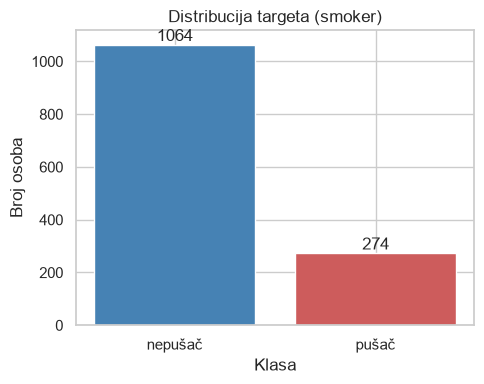

In [9]:
fig, ax = plt.subplots(figsize=(5, 4))
counts = target.value_counts().sort_index()
bars = ax.bar(CLASS_LABELS, counts.values, color=["steelblue", "indianred"])
ax.bar_label(bars, fmt="%d")
ax.set_title("Distribucija targeta (smoker)")
ax.set_xlabel("Klasa")
ax.set_ylabel("Broj osoba")
save_and_show(fig, "target_distribution.png")

# Klase su neuravnotežene: nepušača je oko 79.5 %, a pušača oko 20.5 %. Zbog toga `accuracy`
# sam po sebi nije dovoljan pokazatelj kvalitete modela jer model koji uvijek predvidi
# "nepušač" ima točnost oko 79 %, ali ne prepoznaje nijednog pušača. Zato uz `accuracy`
# računam i `balanced accuracy`, `precision`, `recall` i `F1`, a u tablice uključujem i
# baseline model (`DummyClassifier`, uvijek najčešća klasa).

# ## 3. Eksploratorna analiza prema statusu pušača
#
# Zanimljivo je vidjeti razlikuju li se pušači i nepušači po dobi, BMI-u, spolu, regiji i broju
# djece. Grafovi pokazuju distribucije, a tablica ispod udjele pušača po skupinama.

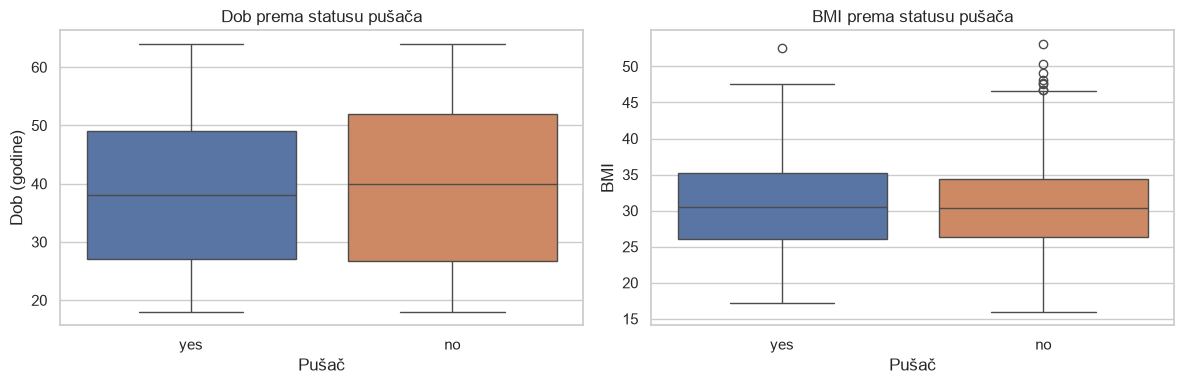

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="smoker", y="age", ax=axes[0], hue="smoker", legend=False)
axes[0].set_title("Dob prema statusu pušača")
axes[0].set_xlabel("Pušač")
axes[0].set_ylabel("Dob (godine)")
sns.boxplot(data=df, x="smoker", y="bmi", ax=axes[1], hue="smoker", legend=False)
axes[1].set_title("BMI prema statusu pušača")
axes[1].set_xlabel("Pušač")
axes[1].set_ylabel("BMI")
save_and_show(fig, "eda_age_bmi_vs_smoker.png")

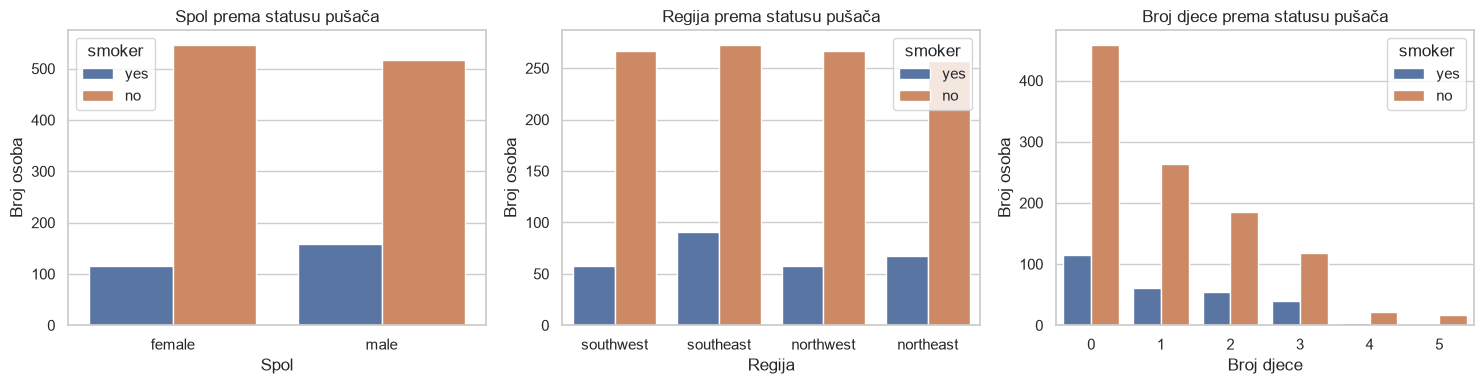

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x="sex", hue="smoker", ax=axes[0])
axes[0].set_title("Spol prema statusu pušača")
axes[0].set_xlabel("Spol")
axes[0].set_ylabel("Broj osoba")
sns.countplot(data=df, x="region", hue="smoker", ax=axes[1])
axes[1].set_title("Regija prema statusu pušača")
axes[1].set_xlabel("Regija")
axes[1].set_ylabel("Broj osoba")
sns.countplot(data=df, x="children", hue="smoker", ax=axes[2])
axes[2].set_title("Broj djece prema statusu pušača")
axes[2].set_xlabel("Broj djece")
axes[2].set_ylabel("Broj osoba")
save_and_show(fig, "eda_categorical_vs_smoker.png")

In [12]:
smoker_rate_by_group = pd.DataFrame(
    {
        "spol": df.groupby("sex")["smoker"].apply(lambda values: (values == "yes").mean()).round(3),
        "regija": df.groupby("region")["smoker"].apply(lambda values: (values == "yes").mean()).round(3),
    }
)
smoker_rate_by_group

,spol,regija
female,0.174,NaN
male,0.235,NaN
northeast,NaN,0.207
northwest,NaN,0.178
southeast,NaN,0.250
southwest,NaN,0.178


In [13]:
bmi_over_30 = df["bmi"] > 30
print("Udio pušača kod BMI > 30:", round((df.loc[bmi_over_30, "smoker"] == "yes").mean(), 3))
print("Udio pušača kod BMI <= 30:", round((df.loc[~bmi_over_30, "smoker"] == "yes").mean(), 3))
print("Prosječna dob pušača:", round(df.loc[df["smoker"] == "yes", "age"].mean(), 1))
print("Prosječna dob nepušača:", round(df.loc[df["smoker"] == "no", "age"].mean(), 1))

Udio pušača kod BMI > 30: 0.204
Udio pušača kod BMI <= 30: 0.205
Prosječna dob pušača: 38.5
Prosječna dob nepušača: 39.4


# Razlike po spolu i regiji su male, a kod dobi i BMI-a su vidljive: pušači su u prosjeku nešto
# stariji i imaju nešto veći udio osoba s BMI-om iznad 30. To znači da značajke nose određenu
# informaciju, ali je očekivano da točnost neće biti vrlo visoka budući da se status pušača iz ovih
# varijabli ne može odrediti sa sigurnošću.

# ## 4. Preprocessing i podjela podataka
#
# Broj djece ostavljam kao numeričku varijablu, a `sex` i `region` one-hot kodiram. Scaler
# koristim kod modela osjetljivih na mjerilo (Logistic Regression i neuronske mreže), dok
# Random Forest i XGBoost rade bez skaliranja.
#
# Podjela je 80/20 sa `stratify=y`, čime se u trening i test skup prenose isti udjeli klasa.
# Bez toga bi zbog neuravnoteženosti lako moglo doći do toga da test skup sadrži bitno drugačiji
# udio pušača od trening skupa, pa bi rezultati ovisili o sretnoj podjeli. Iz trening skupa se
# dodatno izdvaja validacijski dio za rano zaustavljanje mreža.

In [14]:
X = df.drop(columns=[TARGET_SOURCE, "charges"])
y = target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=VALIDATION_SPLIT, random_state=SEED, stratify=y_train
)

print(f"Trening: {X_train.shape[0]} uzoraka ({100 * (1 - TEST_SIZE):.0f}%)")
print(f"Validacija: {X_val.shape[0]} uzoraka (izdvojeno iz trening skupa)")
print(f"Test: {X_test.shape[0]} uzoraka ({100 * TEST_SIZE:.0f}%)")

class_shares = pd.DataFrame(
    {
        "trening": y_train.value_counts(normalize=True),
        "validacija": y_val.value_counts(normalize=True),
        "test": y_test.value_counts(normalize=True),
    }
).round(4)
class_shares.index = CLASS_LABELS
class_shares

Trening: 856 uzoraka (80%)
Validacija: 214 uzoraka (izdvojeno iz trening skupa)
Test: 268 uzoraka (20%)


,trening,validacija,test
nepušač,0.7956,0.7944,0.7948
pušač,0.2044,0.2056,0.2052


In [15]:
preprocessor_check = build_preprocessor(StandardScaler())
prepared_columns = list(preprocessor_check.fit_transform(X_train).columns)
print(f"Broj značajki nakon obrade: {len(prepared_columns)}")
print(prepared_columns)

Broj značajki nakon obrade: 9
['age', 'bmi', 'children', 'sex_female', 'sex_male', 'region_northeast', 'region_northwest', 'region_southeast', 'region_southwest']


# ## 5. Klasični modeli
#
# Uz tri tražena modela (Logistic Regression, Random Forest, XGBoost) treniram i baseline koji
# uvijek predviđa najčešću klasu. Baseline je referenca: model je koristan samo ako je bolji od
# njega.

In [16]:
classical_models = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline(
        [
            ("prep", build_preprocessor(StandardScaler())),
            ("model", LogisticRegression(max_iter=1000, random_state=SEED)),
        ]
    ),
    "Random Forest": Pipeline(
        [
            ("prep", build_preprocessor()),
            (
                "model",
                RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
            ),
        ]
    ),
    "XGBoost": Pipeline(
        [
            ("prep", build_preprocessor()),
            (
                "model",
                XGBClassifier(
                    n_estimators=300,
                    max_depth=3,
                    learning_rate=0.05,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    random_state=SEED,
                    eval_metric="logloss",
                    n_jobs=-1,
                ),
            ),
        ]
    ),
}

classical_predictions = {}
classical_rows = []

for name, model in classical_models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    classical_predictions[name] = predicted
    classical_rows.append({"Model": name, "Type": "Classical", **classification_metrics(y_test, predicted)})

classical_results = pd.DataFrame(classical_rows)
classical_results.to_csv(OUTPUT_DIR / "classification_classical_results.csv", index=False)
classical_results.round(4)

,Model,Type,Accuracy,Balanced accuracy,Precision,Recall,F1
0,Baseline (majority),Classical,0.7948,0.5000,0.0000,0.0000,0.0000
1,Logistic Regression,Classical,0.7948,0.5000,0.0000,0.0000,0.0000
2,Random Forest,Classical,0.7500,0.4921,0.1667,0.0545,0.0822
3,XGBoost,Classical,0.7575,0.4765,0.0000,0.0000,0.0000


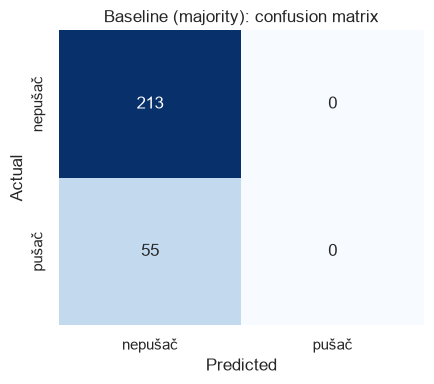

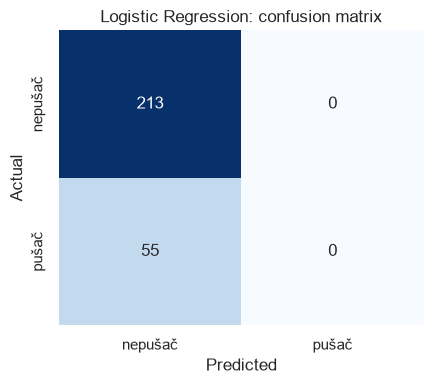

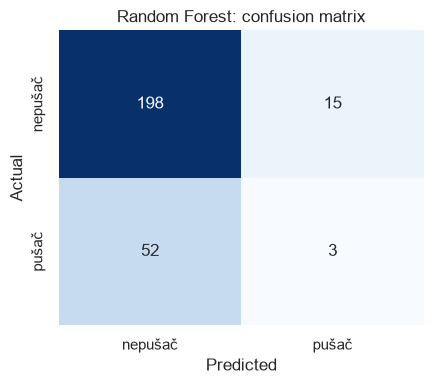

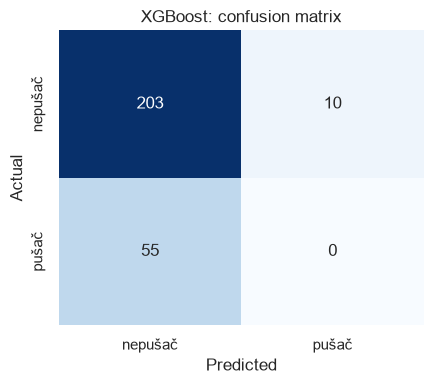

In [17]:
confusion_matrices = {}

for name, predicted in classical_predictions.items():
    confusion_matrices[name] = plot_confusion_matrix(
        y_test,
        predicted,
        f"{name}: confusion matrix",
        f"confusion_matrix_{slugify(name)}.png",
    )

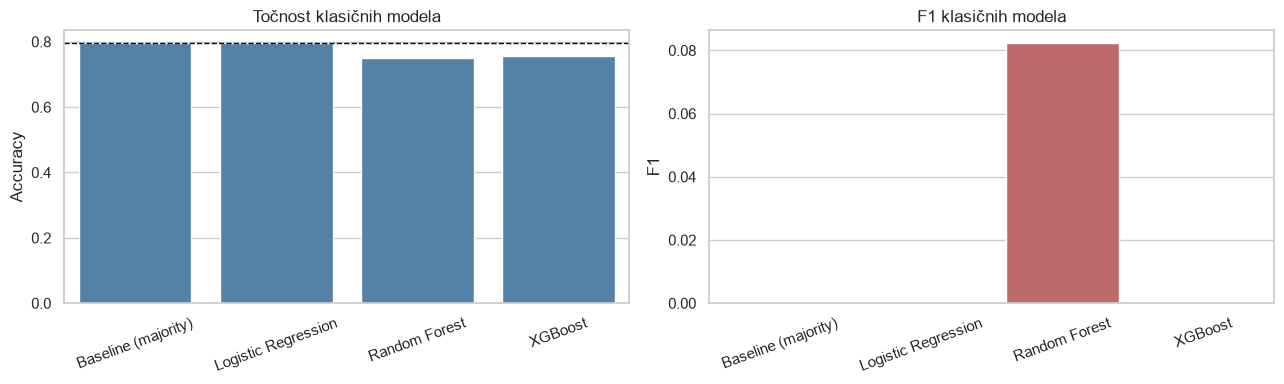

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=classical_results, x="Model", y="Accuracy", ax=axes[0], color="steelblue")
axes[0].set_title("Točnost klasičnih modela")
axes[0].set_xlabel("")
axes[0].set_ylabel("Accuracy")
axes[0].tick_params(axis="x", rotation=20)
axes[0].axhline(classical_results.loc[0, "Accuracy"], color="black", linestyle="--", linewidth=1)
sns.barplot(data=classical_results, x="Model", y="F1", ax=axes[1], color="indianred")
axes[1].set_title("F1 klasičnih modela")
axes[1].set_xlabel("")
axes[1].set_ylabel("F1")
axes[1].tick_params(axis="x", rotation=20)
save_and_show(fig, "classical_models_barplot.png")

# ## 6. Neuronske mreže
#
# Prva mreža ima dva skrivena sloja (64 i 32 neurona, ReLU). Druga mreža ima tri skrivena sloja
# (128 ReLU, 64 tanh, 32 ReLU), Dropout slojeve i manji `batch_size`. Obje mreže na izlazu imaju
# jedan neuron sa sigmoid aktivacijom i koriste `binary_crossentropy`, što je standardna
# kombinacija za binarnu klasifikaciju. Vjerojatnosti pretvaram u klase s pragom 0.5.

In [19]:
preprocessor_nn = build_preprocessor(StandardScaler())
X_train_nn = np.asarray(preprocessor_nn.fit_transform(X_train), dtype="float32")
X_test_nn = np.asarray(preprocessor_nn.transform(X_test), dtype="float32")

print(f"Trening matrica za mreže: {X_train_nn.shape}")
print(f"Testna matrica za mreže: {X_test_nn.shape}")

Trening matrica za mreže: (856, 9)
Testna matrica za mreže: (268, 9)


In [20]:
nn1_model, nn1_history, nn1_probabilities, nn1_predicted, nn1_metrics = train_classification_nn(
    "Neural Network 1",
    X_train_nn,
    X_test_nn,
    hidden_layers=[64, 32],
    activations=["relu", "relu"],
    dropout_rate=0.0,
    loss="binary_crossentropy",
    batch_size=32,
)
pd.Series(nn1_metrics)

Accuracy                        0.794776
Balanced accuracy                    0.5
Precision                            0.0
Recall                               0.0
F1                                   0.0
Model                   Neural Network 1
Type                              Neural
Slojevi                                2
Neuroni                            64-32
Aktivacije                     relu+relu
Dropout                              0.0
Loss                 binary_crossentropy
Optimizer                           adam
batch_size                            32
Epohe                                 14
dtype: object

In [21]:
nn2_model, nn2_history, nn2_probabilities, nn2_predicted, nn2_metrics = train_classification_nn(
    "Neural Network 2",
    X_train_nn,
    X_test_nn,
    hidden_layers=[128, 64, 32],
    activations=["relu", "tanh", "relu"],
    dropout_rate=[0.5, 0.2, 0.0],
    loss="binary_crossentropy",
    batch_size=16,
)
pd.Series(nn2_metrics)

Accuracy                        0.794776
Balanced accuracy                    0.5
Precision                            0.0
Recall                               0.0
F1                                   0.0
Model                   Neural Network 2
Type                              Neural
Slojevi                                3
Neuroni                        128-64-32
Aktivacije                relu+tanh+relu
Dropout                            lista
Loss                 binary_crossentropy
Optimizer                           adam
batch_size                            16
Epohe                                 13
dtype: object

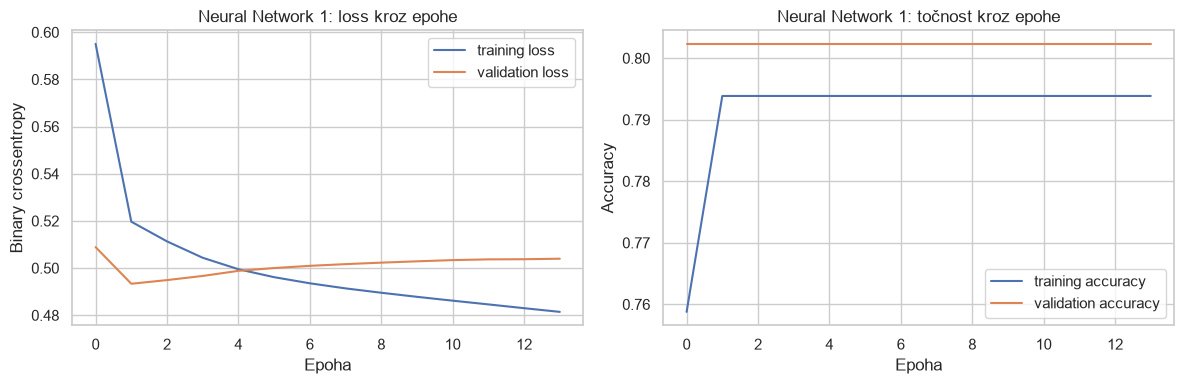

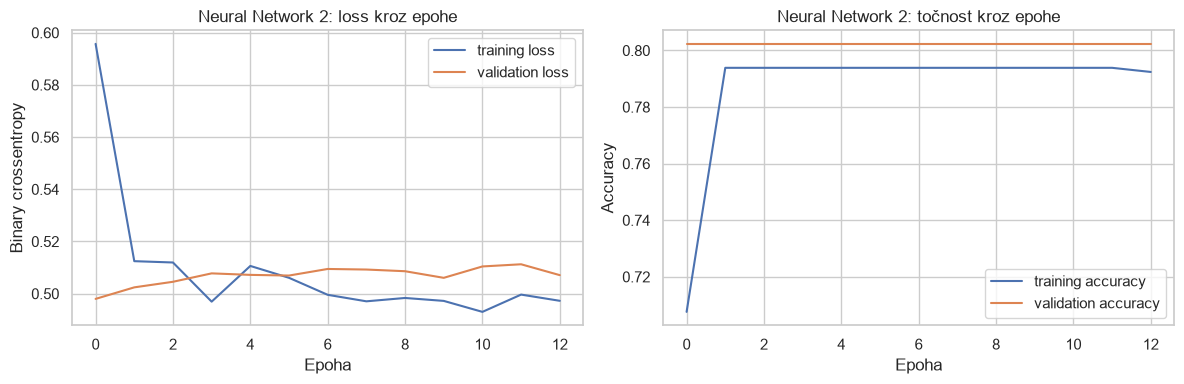

In [22]:
histories = {"Neural Network 1": nn1_history, "Neural Network 2": nn2_history}

for name, history in histories.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history["loss"], label="training loss")
    axes[0].plot(history.history["val_loss"], label="validation loss")
    axes[0].set_title(f"{name}: loss kroz epohe")
    axes[0].set_xlabel("Epoha")
    axes[0].set_ylabel("Binary crossentropy")
    axes[0].legend()
    axes[1].plot(history.history["accuracy"], label="training accuracy")
    axes[1].plot(history.history["val_accuracy"], label="validation accuracy")
    axes[1].set_title(f"{name}: točnost kroz epohe")
    axes[1].set_xlabel("Epoha")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    save_and_show(fig, f"history_{slugify(name)}.png")

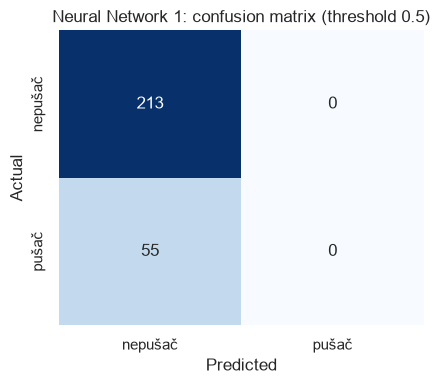

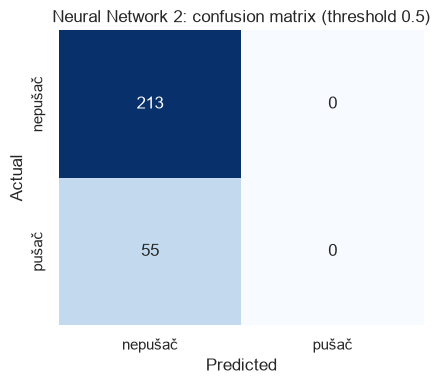

In [23]:
neural_predictions = {"Neural Network 1": nn1_predicted, "Neural Network 2": nn2_predicted}

for name, predicted in neural_predictions.items():
    confusion_matrices[name] = plot_confusion_matrix(
        y_test,
        predicted,
        f"{name}: confusion matrix (threshold 0.5)",
        f"confusion_matrix_{slugify(name)}.png",
    )

In [24]:
probability_summary = pd.DataFrame(
    {
        "Neural Network 1": nn1_probabilities,
        "Neural Network 2": nn2_probabilities,
    }
).describe().round(3)
print("Sažetak predviđenih vjerojatnosti na testnom skupu:")
probability_summary

Sažetak predviđenih vjerojatnosti na testnom skupu:


,Neural Network 1,Neural Network 2
count,268.000,268.000
mean,0.202,0.187
std,0.049,0.044
min,0.085,0.095
25%,0.164,0.155
50%,0.192,0.187
75%,0.236,0.216
max,0.319,0.307


# ## 7. Zajednička tablica rezultata
#
# Usporedba baselinea, klasičnih modela i neuronskih mreža. Uz `accuracy` prikazujem i metrike
# koje bolje opisuju rad na neuravnoteženim klasama.

In [25]:
all_results = pd.concat(
    [
        classical_results,
        pd.DataFrame([nn1_metrics, nn2_metrics])[
            ["Model", "Type", "Accuracy", "Balanced accuracy", "Precision", "Recall", "F1"]
        ],
    ],
    ignore_index=True,
)
all_results = all_results[
    ["Model", "Type", "Accuracy", "Balanced accuracy", "Precision", "Recall", "F1"]
].round(4)
all_results.to_csv(OUTPUT_DIR / "classification_results.csv", index=False)
all_results

,Model,Type,Accuracy,Balanced accuracy,Precision,Recall,F1
0,Baseline (majority),Classical,0.7948,0.5000,0.0000,0.0000,0.0000
1,Logistic Regression,Classical,0.7948,0.5000,0.0000,0.0000,0.0000
2,Random Forest,Classical,0.7500,0.4921,0.1667,0.0545,0.0822
3,XGBoost,Classical,0.7575,0.4765,0.0000,0.0000,0.0000
4,Neural Network 1,Neural,0.7948,0.5000,0.0000,0.0000,0.0000
5,Neural Network 2,Neural,0.7948,0.5000,0.0000,0.0000,0.0000


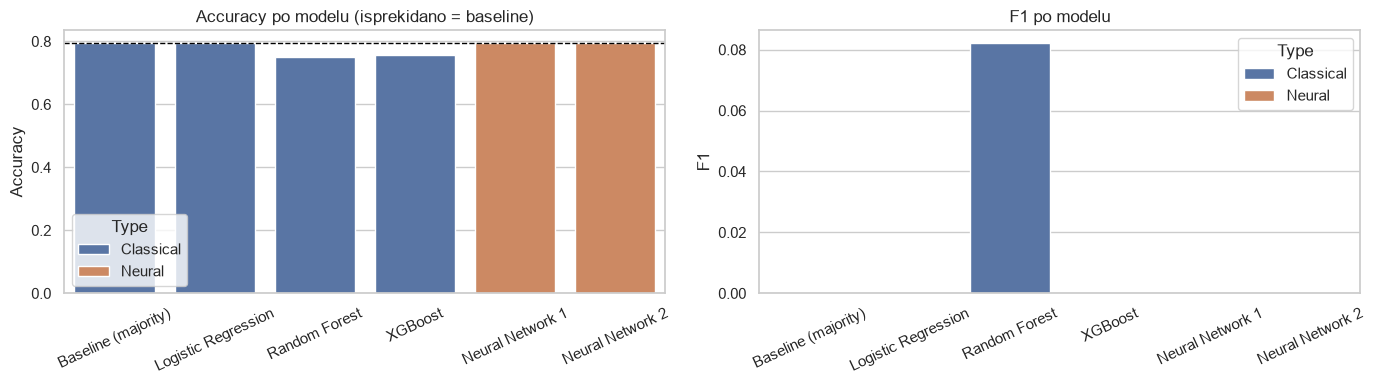

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=all_results, x="Model", y="Accuracy", hue="Type", ax=axes[0])
axes[0].axhline(all_results.loc[0, "Accuracy"], color="black", linestyle="--", linewidth=1)
axes[0].set_title("Accuracy po modelu (isprekidano = baseline)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Accuracy")
axes[0].tick_params(axis="x", rotation=25)
sns.barplot(data=all_results, x="Model", y="F1", hue="Type", ax=axes[1])
axes[1].set_title("F1 po modelu")
axes[1].set_xlabel("")
axes[1].set_ylabel("F1")
axes[1].tick_params(axis="x", rotation=25)
save_and_show(fig, "classification_results_barplot.png")

# U glavnoj tablici svi modeli imaju `accuracy` jednak baselineu (0.7948) ili niži, a `F1` im je
# nula ili blizu nule. To znači da modeli u praksi predviđaju samo klasu "nepušač": baseline i
# XGBoost ne pronađu nijednog pušača, Logistic Regression i mreže također (recall 0), dok Random
# Forest pronađe svega oko 3 od 55 pušača u testnom skupu (recall 0.0545). Zbog toga je za ovaj
# zadatak nužno gledati i druge metrike (`balanced accuracy`, `recall`, `F1` i ROC AUC), a ne
# samo `accuracy`, koja ovdje nagrađuje model koji uvijek kaže "nepušač".

# ## 8. Eksperimenti
#
# Kao i kod regresije, u svakom eksperimentu mijenjam jedan element, a ostalo ostaje isto kao kod
# mreže 1 (dva skrivena sloja, ReLU, Adam, `batch_size = 32`, bez Dropouta, standardno
# skaliranje).

In [27]:
base_hidden_layers = [64, 32]
base_activations = ["relu", "relu"]
base_batch_size = 32
base_optimizer = "adam"
base_loss = "binary_crossentropy"

CLASSIFICATION_NN_COLUMNS = [
    "Model", "Slojevi", "Neuroni", "Aktivacije", "Dropout", "Loss", "Optimizer",
    "batch_size", "Epohe", "Accuracy", "Balanced accuracy", "Precision", "Recall", "F1",
]


def neural_inputs(scaler):
    """Vraća (trening, test) matrice značajki za zadanu metodu skaliranja."""
    preprocessor = build_preprocessor(scaler)
    train_input = np.asarray(preprocessor.fit_transform(X_train), dtype="float32")
    test_input = np.asarray(preprocessor.transform(X_test), dtype="float32")
    return train_input, test_input


def experiment_table(metrics_list):
    return pd.DataFrame(metrics_list)[CLASSIFICATION_NN_COLUMNS].round(4)

# ### 8.1 Utjecaj skaliranja
#
# Bez skaliranja numeričke varijable imaju različite raspone (`age` do 64, `bmi` oko 30,
# `children` do 5), što kod Logistic Regression i neuronskih mreža otežava učenje.

In [28]:
scaling_rows = []
scaling_nn_metrics = []

for variant, scaler in {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "Bez skaliranja": None,
}.items():
    logistic_model = Pipeline(
        [
            ("prep", build_preprocessor(scaler)),
            ("model", LogisticRegression(max_iter=1000, random_state=SEED)),
        ]
    )
    logistic_model.fit(X_train, y_train)
    scaling_rows.append(
        {
            "Model": "Logistic Regression",
            "Scaler": variant,
            "Accuracy": accuracy_score(y_test, logistic_model.predict(X_test)),
        }
    )

    train_input, test_input = neural_inputs(scaler)
    _, _, _, _, metrics = train_classification_nn(
        f"Neural Network 1 ({variant})", train_input, test_input,
        base_hidden_layers, base_activations, batch_size=base_batch_size,
    )
    scaling_rows.append({"Model": "Neural Network 1", "Scaler": variant, "Accuracy": metrics["Accuracy"]})
    scaling_nn_metrics.append(metrics)

scaling_results = pd.DataFrame(scaling_rows).round(4)
scaling_results.to_csv(OUTPUT_DIR / "classification_scaling_experiment.csv", index=False)
scaling_results

,Model,Scaler,Accuracy
0,Logistic Regression,StandardScaler,0.7948
1,Neural Network 1,StandardScaler,0.7948
2,Logistic Regression,MinMaxScaler,0.7948
3,Neural Network 1,MinMaxScaler,0.7948
4,Logistic Regression,Bez skaliranja,0.7948
5,Neural Network 1,Bez skaliranja,0.7948


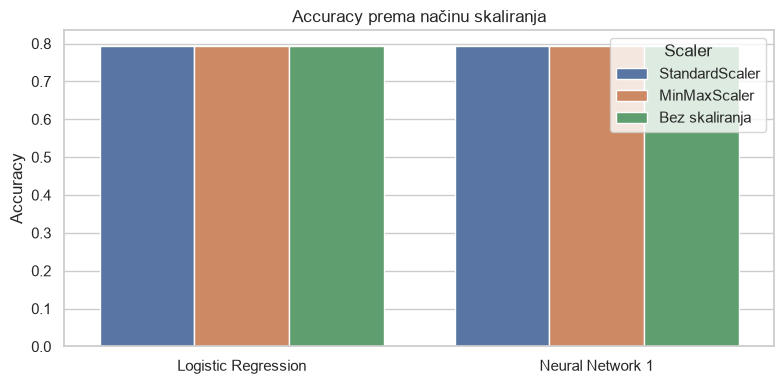

In [29]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=scaling_results, x="Model", y="Accuracy", hue="Scaler", ax=ax)
ax.set_title("Accuracy prema načinu skaliranja")
ax.set_xlabel("")
ax.set_ylabel("Accuracy")
save_and_show(fig, "experiment_scaling.png")

# ### 8.2 Utjecaj `batch_size`
#
# Uz `batch_size = 1` mreža radi jedan korak po uzorku, pa je broj epoha ograničen na 30.

In [30]:
batch_size_rows = []

for batch_size in [1, 16, 32, 64, 128]:
    _, _, _, _, metrics = train_classification_nn(
        f"batch_size = {batch_size}", X_train_nn, X_test_nn,
        base_hidden_layers, base_activations,
        batch_size=batch_size, max_epochs=30 if batch_size == 1 else 150,
    )
    batch_size_rows.append(metrics)

batch_size_results = experiment_table(batch_size_rows)
batch_size_results.to_csv(OUTPUT_DIR / "classification_batch_size_experiment.csv", index=False)
batch_size_results

,Model,Slojevi,Neuroni,Aktivacije,Dropout,Loss,Optimizer,batch_size,Epohe,Accuracy,Balanced accuracy,Precision,Recall,F1
0,batch_size = 1,2,64-32,relu+relu,0.0,binary_crossentropy,adam,1,13,0.7948,0.5,0.0,0.0,0.0
1,batch_size = 16,2,64-32,relu+relu,0.0,binary_crossentropy,adam,16,13,0.7948,0.5,0.0,0.0,0.0
2,batch_size = 32,2,64-32,relu+relu,0.0,binary_crossentropy,adam,32,14,0.7948,0.5,0.0,0.0,0.0
3,batch_size = 64,2,64-32,relu+relu,0.0,binary_crossentropy,adam,64,15,0.7948,0.5,0.0,0.0,0.0
4,batch_size = 128,2,64-32,relu+relu,0.0,binary_crossentropy,adam,128,17,0.7948,0.5,0.0,0.0,0.0


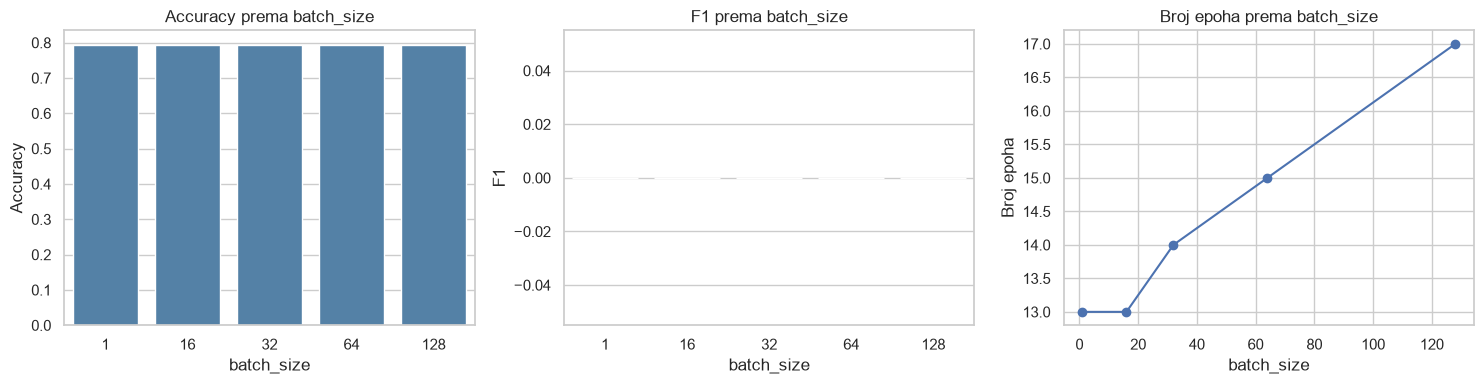

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=batch_size_results, x="batch_size", y="Accuracy", ax=axes[0], color="steelblue")
axes[0].set_title("Accuracy prema batch_size")
axes[0].set_xlabel("batch_size")
axes[0].set_ylabel("Accuracy")
sns.barplot(data=batch_size_results, x="batch_size", y="F1", ax=axes[1], color="indianred")
axes[1].set_title("F1 prema batch_size")
axes[1].set_xlabel("batch_size")
axes[1].set_ylabel("F1")
axes[2].plot(batch_size_results["batch_size"], batch_size_results["Epohe"], marker="o")
axes[2].set_title("Broj epoha prema batch_size")
axes[2].set_xlabel("batch_size")
axes[2].set_ylabel("Broj epoha")
save_and_show(fig, "experiment_batch_size.png")

# ### 8.3 Utjecaj aktivacijske funkcije
#
# Mijenjam aktivaciju u skrivenim slojevima. Izlazni sloj ostaje `Dense(1, sigmoid)` jer je
# zadatak binarna klasifikacija; `softmax` je namijenjen višeklasnom izlazu (npr. da se
# predviđa regija), pa ga ovdje nema smisla koristiti.

In [32]:
activation_rows = []

for activation in ["relu", "tanh", "sigmoid"]:
    _, _, _, _, metrics = train_classification_nn(
        f"aktivacija = {activation}", X_train_nn, X_test_nn,
        base_hidden_layers, [activation] * len(base_hidden_layers),
        batch_size=base_batch_size,
    )
    activation_rows.append(metrics)

activation_results = experiment_table(activation_rows)
activation_results.to_csv(OUTPUT_DIR / "classification_activation_experiment.csv", index=False)
activation_results

,Model,Slojevi,Neuroni,Aktivacije,Dropout,Loss,Optimizer,batch_size,Epohe,Accuracy,Balanced accuracy,Precision,Recall,F1
0,aktivacija = relu,2,64-32,relu+relu,0.0,binary_crossentropy,adam,32,14,0.7948,0.5,0.0,0.0,0.0
1,aktivacija = tanh,2,64-32,tanh+tanh,0.0,binary_crossentropy,adam,32,14,0.7948,0.5,0.0,0.0,0.0
2,aktivacija = sigmoid,2,64-32,sigmoid+sigmoid,0.0,binary_crossentropy,adam,32,13,0.7948,0.5,0.0,0.0,0.0


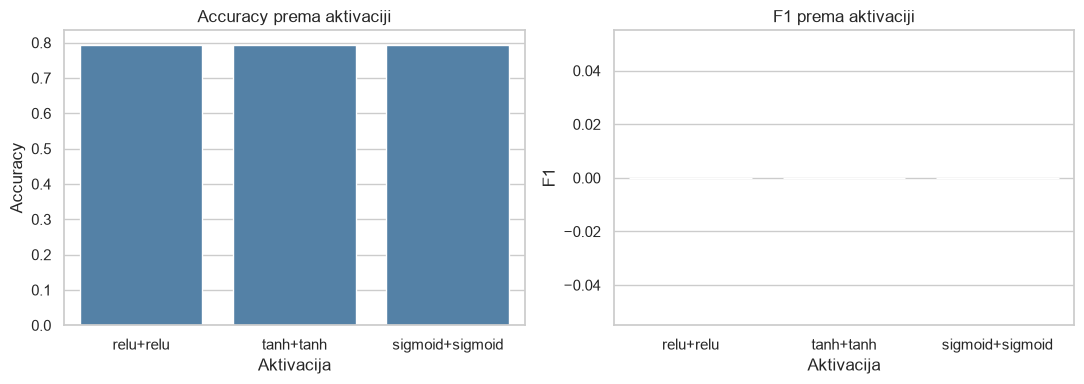

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=activation_results, x="Aktivacije", y="Accuracy", ax=axes[0], color="steelblue")
axes[0].set_title("Accuracy prema aktivaciji")
axes[0].set_xlabel("Aktivacija")
axes[0].set_ylabel("Accuracy")
sns.barplot(data=activation_results, x="Aktivacije", y="F1", ax=axes[1], color="indianred")
axes[1].set_title("F1 prema aktivaciji")
axes[1].set_xlabel("Aktivacija")
axes[1].set_ylabel("F1")
save_and_show(fig, "experiment_activation.png")

# ### 8.4 Utjecaj Dropouta
#
# Dropout se dodaje iza skrivenih slojeva mreže s tri sloja (128 -> 64 -> 32).

In [34]:
dropout_rows = []
dropout_layers = [128, 64, 32]

for dropout_rate in [0.0, 0.2, 0.5]:
    _, _, _, _, metrics = train_classification_nn(
        f"dropout = {dropout_rate}", X_train_nn, X_test_nn,
        dropout_layers, ["relu"] * len(dropout_layers),
        dropout_rate=dropout_rate, batch_size=base_batch_size,
    )
    dropout_rows.append(metrics)

dropout_results = experiment_table(dropout_rows)
dropout_results.to_csv(OUTPUT_DIR / "classification_dropout_experiment.csv", index=False)
dropout_results

,Model,Slojevi,Neuroni,Aktivacije,Dropout,Loss,Optimizer,batch_size,Epohe,Accuracy,Balanced accuracy,Precision,Recall,F1
0,dropout = 0.0,3,128-64-32,relu+relu+relu,0.0,binary_crossentropy,adam,32,15,0.7948,0.5,0.0,0.0,0.0
1,dropout = 0.2,3,128-64-32,relu+relu+relu,0.2,binary_crossentropy,adam,32,14,0.7948,0.5,0.0,0.0,0.0
2,dropout = 0.5,3,128-64-32,relu+relu+relu,0.5,binary_crossentropy,adam,32,15,0.7948,0.5,0.0,0.0,0.0


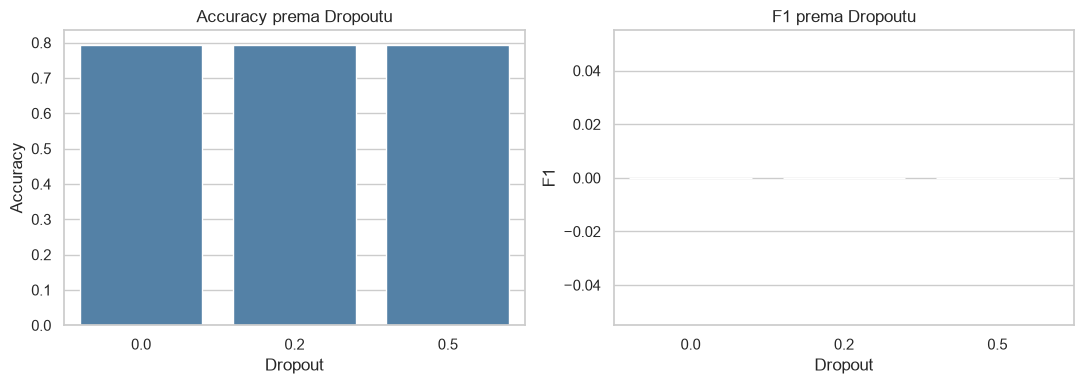

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=dropout_results, x="Dropout", y="Accuracy", ax=axes[0], color="steelblue")
axes[0].set_title("Accuracy prema Dropoutu")
axes[0].set_xlabel("Dropout")
axes[0].set_ylabel("Accuracy")
sns.barplot(data=dropout_results, x="Dropout", y="F1", ax=axes[1], color="indianred")
axes[1].set_title("F1 prema Dropoutu")
axes[1].set_xlabel("Dropout")
axes[1].set_ylabel("F1")
save_and_show(fig, "experiment_dropout.png")

# ### 8.5 Utjecaj funkcije gubitka
#
# `binary_crossentropy` je standardna funkcija za binarnu klasifikaciju sa sigmoid izlazom.
# Usporedba s `mse` pokazuje što se dobije ako se za isti model koristi funkcija namijenjena
# regresiji.

In [36]:
loss_rows = []

for loss in ["binary_crossentropy", "mse"]:
    _, _, _, _, metrics = train_classification_nn(
        f"loss = {loss}", X_train_nn, X_test_nn,
        base_hidden_layers, base_activations, loss=loss, batch_size=base_batch_size,
    )
    loss_rows.append(metrics)

loss_results = experiment_table(loss_rows)
loss_results.to_csv(OUTPUT_DIR / "classification_loss_experiment.csv", index=False)
loss_results

,Model,Slojevi,Neuroni,Aktivacije,Dropout,Loss,Optimizer,batch_size,Epohe,Accuracy,Balanced accuracy,Precision,Recall,F1
0,loss = binary_crossentropy,2,64-32,relu+relu,0.0,binary_crossentropy,adam,32,14,0.7948,0.5,0.0,0.0,0.0
1,loss = mse,2,64-32,relu+relu,0.0,mse,adam,32,14,0.7948,0.5,0.0,0.0,0.0


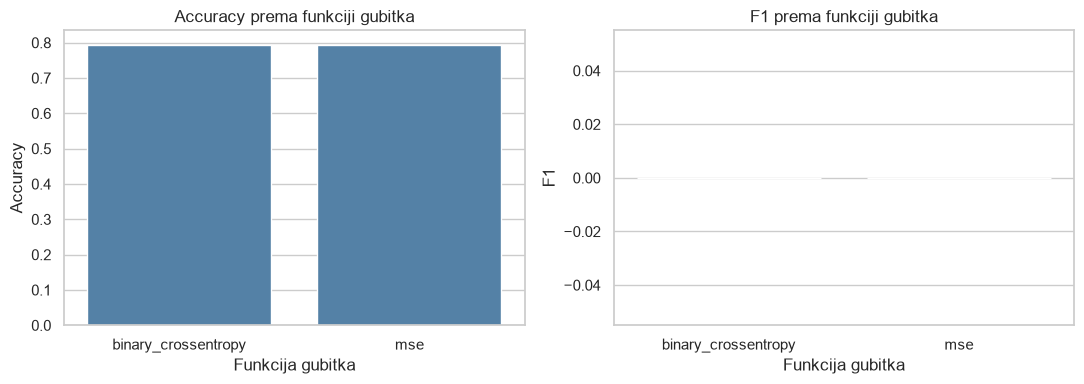

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=loss_results, x="Loss", y="Accuracy", ax=axes[0], color="steelblue")
axes[0].set_title("Accuracy prema funkciji gubitka")
axes[0].set_xlabel("Funkcija gubitka")
axes[0].set_ylabel("Accuracy")
sns.barplot(data=loss_results, x="Loss", y="F1", ax=axes[1], color="indianred")
axes[1].set_title("F1 prema funkciji gubitka")
axes[1].set_xlabel("Funkcija gubitka")
axes[1].set_ylabel("F1")
save_and_show(fig, "experiment_loss.png")

# ### 8.6 Utjecaj uravnoteženja klasa (`class_weight`)
#
# Budući da je udio pušača oko 20 %, modeli koji minimiziraju ukupnu pogrešku gotovo uvijek
# predviđaju klasu "nepušač". Zato testiram i varijante koje daju veću težinu rjeđoj klasi.

In [38]:
class_weights = {0: 1.0, 1: round((y_train == 0).sum() / (y_train == 1).sum(), 2)}
print("Težine klasa (0 = nepušač, 1 = pušač):", class_weights)

balanced_models = {
    "Logistic Regression (balanced)": Pipeline(
        [
            ("prep", build_preprocessor(StandardScaler())),
            ("model", LogisticRegression(max_iter=1000, random_state=SEED, class_weight="balanced")),
        ]
    ),
    "Random Forest (balanced)": Pipeline(
        [
            ("prep", build_preprocessor()),
            (
                "model",
                RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1, class_weight="balanced"),
            ),
        ]
    ),
    "XGBoost (balanced)": Pipeline(
        [
            ("prep", build_preprocessor()),
            (
                "model",
                XGBClassifier(
                    n_estimators=300,
                    max_depth=3,
                    learning_rate=0.05,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    random_state=SEED,
                    eval_metric="logloss",
                    scale_pos_weight=class_weights[1],
                    n_jobs=-1,
                ),
            ),
        ]
    ),
}

balanced_rows = []
balanced_predictions = {}

for name, model in balanced_models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    balanced_predictions[name] = predicted
    balanced_rows.append({"Model": name, "Type": "Classical (balanced)", **classification_metrics(y_test, predicted)})

_, _, _, nn_balanced_predicted, nn_balanced_metrics = train_classification_nn(
    "Neural Network 1 (balanced)", X_train_nn, X_test_nn, base_hidden_layers, base_activations,
    batch_size=base_batch_size, class_weight=class_weights,
)
balanced_predictions["Neural Network 1 (balanced)"] = nn_balanced_predicted
balanced_nn_metrics = [nn_balanced_metrics]

balanced_results = pd.concat(
    [
        pd.DataFrame(balanced_rows),
        pd.DataFrame(balanced_nn_metrics)[
            ["Model", "Type", "Accuracy", "Balanced accuracy", "Precision", "Recall", "F1"]
        ],
    ],
    ignore_index=True,
)[["Model", "Type", "Accuracy", "Balanced accuracy", "Precision", "Recall", "F1"]].round(4)
balanced_results.to_csv(OUTPUT_DIR / "classification_class_weight_experiment.csv", index=False)
balanced_results

Težine klasa (0 = nepušač, 1 = pušač): {0: 1.0, 1: np.float64(3.89)}


,Model,Type,Accuracy,Balanced accuracy,Precision,Recall,F1
0,Logistic Regression (balanced),Classical (balanced),0.5224,0.5309,0.2256,0.5455,0.3191
1,Random Forest (balanced),Classical (balanced),0.6791,0.4947,0.1961,0.1818,0.1887
2,XGBoost (balanced),Classical (balanced),0.5970,0.4700,0.1728,0.2545,0.2059
3,Neural Network 1 (balanced),Neural,0.5858,0.5236,0.2255,0.4182,0.2930


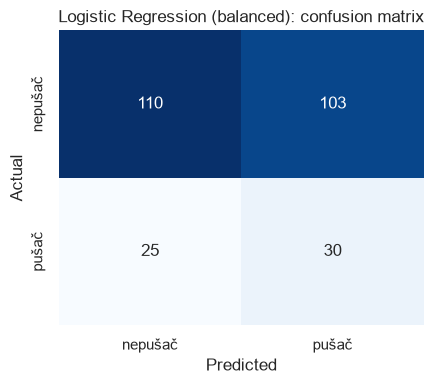

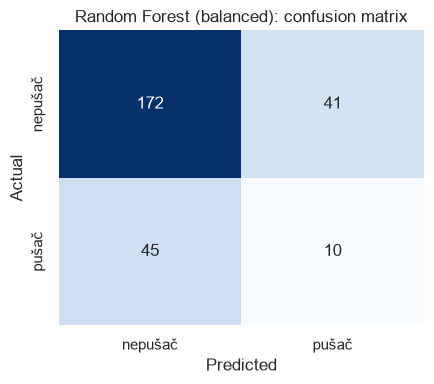

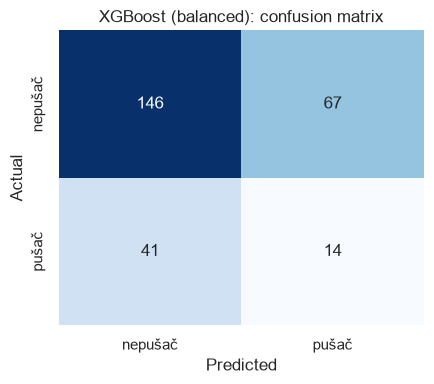

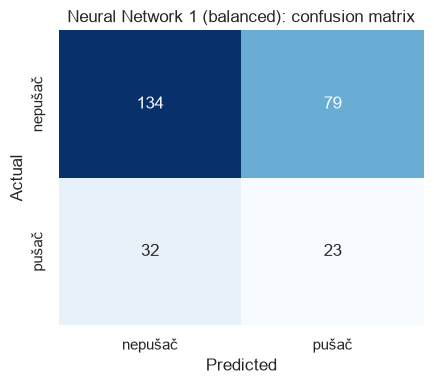

In [39]:
for name, predicted in balanced_predictions.items():
    plot_confusion_matrix(
        y_test,
        predicted,
        f"{name}: confusion matrix",
        f"confusion_matrix_{slugify(name)}.png",
    )

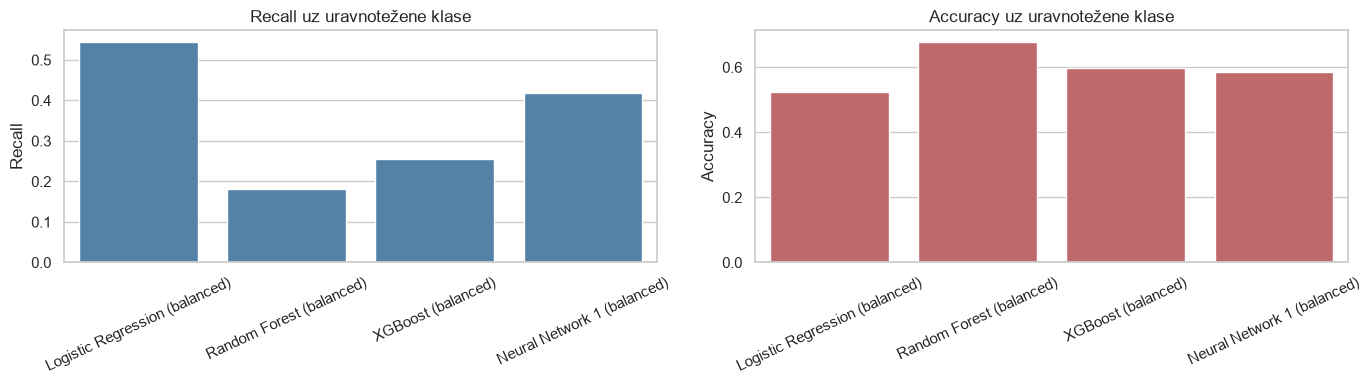

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=balanced_results, x="Model", y="Recall", ax=axes[0], color="steelblue")
axes[0].set_title("Recall uz uravnotežene klase")
axes[0].set_xlabel("")
axes[0].set_ylabel("Recall")
axes[0].tick_params(axis="x", rotation=25)
sns.barplot(data=balanced_results, x="Model", y="Accuracy", ax=axes[1], color="indianred")
axes[1].set_title("Accuracy uz uravnotežene klase")
axes[1].set_xlabel("")
axes[1].set_ylabel("Accuracy")
axes[1].tick_params(axis="x", rotation=25)
save_and_show(fig, "experiment_class_weight.png")

# Uravnoteženje klasa mijenja ponašanje modela: `recall` i `F1` rastu, a `accuracy` pada ispod
# baselinea. To je i očekivano jer model sada stvarno predviđa i rjeđu klasu, pa "plaća" pogreškama
# na češćoj klasi. Bez uravnoteženja svi modeli u praksi predviđaju samo "nepušač".

# ### 8.7 ROC AUC - koliko informacije ima u značajkama
#
# `Accuracy` i `F1` na ovako neuravnoteženim klasama ne odgovaraju na pitanje razlikuju li modeli
# pušače od nepušača. ROC AUC mjeri upravo to: vrijednost 0.5 znači da model ne razlikuje klase
# bolje od slučajnog pogađanja, a 1.0 savršeno razlikovanje. Uz to se AUC računa na 5-strukoj
# stratificiranoj unakrsnoj validaciji, pa ne ovisi o jednoj konkretnoj podjeli podataka.

In [41]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

auc_candidates = {
    "Logistic Regression": Pipeline(
        [
            ("prep", build_preprocessor(StandardScaler())),
            ("model", LogisticRegression(max_iter=1000, random_state=SEED)),
        ]
    ),
    "Random Forest": Pipeline(
        [
            ("prep", build_preprocessor()),
            ("model", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)),
        ]
    ),
    "XGBoost": Pipeline(
        [
            ("prep", build_preprocessor()),
            (
                "model",
                XGBClassifier(
                    n_estimators=300,
                    max_depth=3,
                    learning_rate=0.05,
                    random_state=SEED,
                    eval_metric="logloss",
                    n_jobs=-1,
                ),
            ),
        ]
    ),
}

auc_rows = []

for name, model in auc_candidates.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
    model.fit(X_train, y_train)
    auc_rows.append(
        {
            "Model": name,
            "AUC (5-fold)": round(scores.mean(), 4),
            "AUC std": round(scores.std(), 4),
            "AUC (test)": round(roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]), 4),
        }
    )

auc_rows.append(
    {"Model": "Neural Network 1", "AUC (5-fold)": np.nan, "AUC std": np.nan,
     "AUC (test)": round(roc_auc_score(y_test, nn1_probabilities), 4)}
)
auc_rows.append(
    {"Model": "Neural Network 2", "AUC (5-fold)": np.nan, "AUC std": np.nan,
     "AUC (test)": round(roc_auc_score(y_test, nn2_probabilities), 4)}
)

auc_results = pd.DataFrame(auc_rows)
auc_results.to_csv(OUTPUT_DIR / "classification_auc_comparison.csv", index=False)
auc_results

,Model,AUC (5-fold),AUC std,AUC (test)
0,Logistic Regression,0.5496,0.0406,0.5750
1,Random Forest,0.5182,0.0346,0.4726
2,XGBoost,0.5020,0.0295,0.4599
3,Neural Network 1,NaN,NaN,0.4350
4,Neural Network 2,NaN,NaN,0.5410


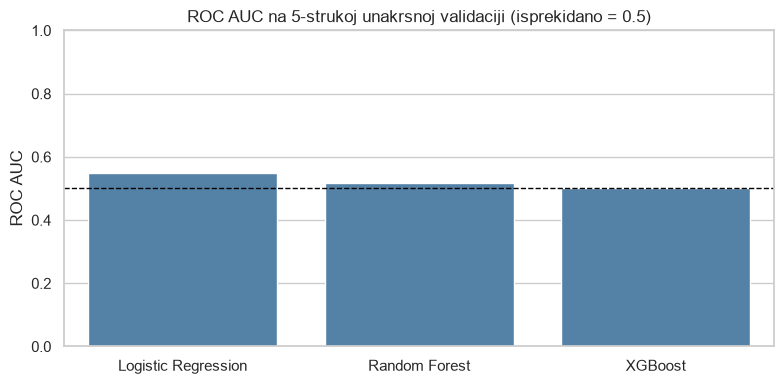

In [42]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=auc_results.dropna(subset=["AUC (5-fold)"]), x="Model", y="AUC (5-fold)", ax=ax, color="steelblue")
ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
ax.set_title("ROC AUC na 5-strukoj unakrsnoj validaciji (isprekidano = 0.5)")
ax.set_xlabel("")
ax.set_ylabel("ROC AUC")
ax.set_ylim(0, 1)
save_and_show(fig, "experiment_auc.png")

# AUC vrijednosti su blizu 0.5. Na 5-strukoj validaciji: Logistic Regression 0.5496 (+/- 0.0406),
# Random Forest 0.5182 (+/- 0.0346) i XGBoost 0.5020 (+/- 0.0295). Na testnom skupu: Logistic
# Regression 0.575, Random Forest 0.4726, XGBoost 0.4599, mreža 1 0.435 i mreža 2 0.541.
#
# Standardna devijacija po foldovima (0.03-0.04) je istog reda veličine kao razlika od 0.5, pa se
# ni za jedan model ne može tvrditi da pouzdano razlikuje pušače od nepušača. Zaključak je da
# varijable `age`, `sex`, `bmi`, `children` i `region` praktički ne nose informaciju o statusu
# pušača. To objašnjava i rezultate iz prethodnih sekcija u kojima svi modeli završe na
# baselineu: modeli rade ispravno, ali ih podaci ne mogu razlikovati.

# ### 8.8 Sažetak svih neuronskih mreža

In [43]:
all_nn_experiments = experiment_table(
    [nn1_metrics, nn2_metrics]
    + scaling_nn_metrics
    + batch_size_rows
    + activation_rows
    + dropout_rows
    + loss_rows
    + balanced_nn_metrics
).sort_values("Accuracy", ascending=False)
all_nn_experiments.to_csv(OUTPUT_DIR / "classification_nn_experiments.csv", index=False)
all_nn_experiments

,Model,Slojevi,Neuroni,Aktivacije,Dropout,Loss,Optimizer,batch_size,Epohe,Accuracy,Balanced accuracy,Precision,Recall,F1
0,Neural Network 1,2,64-32,relu+relu,0.0,binary_crossentropy,adam,32,14,0.7948,0.5000,0.0000,0.0000,0.000
1,Neural Network 2,3,128-64-32,relu+tanh+relu,lista,binary_crossentropy,adam,16,13,0.7948,0.5000,0.0000,0.0000,0.000
2,Neural Network 1 (StandardScaler),2,64-32,relu+relu,0.0,binary_crossentropy,adam,32,14,0.7948,0.5000,0.0000,0.0000,0.000
3,Neural Network 1 (MinMaxScaler),2,64-32,relu+relu,0.0,binary_crossentropy,adam,32,15,0.7948,0.5000,0.0000,0.0000,0.000
4,Neural Network 1 (Bez skaliranja),2,64-32,relu+relu,0.0,binary_crossentropy,adam,32,25,0.7948,0.5000,0.0000,0.0000,0.000
5,batch_size = 1,2,64-32,relu+relu,0.0,binary_crossentropy,adam,1,13,0.7948,0.5000,0.0000,0.0000,0.000
6,batch_size = 16,2,64-32,relu+relu,0.0,binary_crossentropy,adam,16,13,0.7948,0.5000,0.0000,0.0000,0.000
7,batch_size = 32,2,64-32,relu+relu,0.0,binary_crossentropy,adam,32,14,0.7948,0.5000,0.0000,0.0000,0.000
8,batch_size = 64,2,64-32,relu+relu,0.0,binary_crossentropy,adam,64,15,0.7948,0.5000,0.0000,0.0000,0.000
9,batch_size = 128,2,64-32,relu+relu,0.0,binary_crossentropy,adam,128,17,0.7948,0.5000,0.0000,0.0000,0.000


In [44]:
best_nn = all_nn_experiments.iloc[0]
worst_nn = all_nn_experiments.iloc[-1]

print(f"Najbolja mreža: {best_nn['Model']}")
print(f"  Slojevi: {best_nn['Slojevi']} | Neuroni: {best_nn['Neuroni']} | Aktivacije: {best_nn['Aktivacije']}")
print(f"  Dropout: {best_nn['Dropout']} | Loss: {best_nn['Loss']} | batch_size: {best_nn['batch_size']}")
print(f"  Accuracy: {best_nn['Accuracy']:.4f} | Balanced accuracy: {best_nn['Balanced accuracy']:.4f} | F1: {best_nn['F1']:.4f}")
print()
print(f"Najslabija mreža: {worst_nn['Model']}")
print(f"  Slojevi: {worst_nn['Slojevi']} | Neuroni: {worst_nn['Neuroni']} | Aktivacije: {worst_nn['Aktivacije']}")
print(f"  Dropout: {worst_nn['Dropout']} | Loss: {worst_nn['Loss']} | batch_size: {worst_nn['batch_size']}")
print(f"  Accuracy: {worst_nn['Accuracy']:.4f} | Balanced accuracy: {worst_nn['Balanced accuracy']:.4f} | F1: {worst_nn['F1']:.4f}")

Najbolja mreža: Neural Network 1
  Slojevi: 2 | Neuroni: 64-32 | Aktivacije: relu+relu
  Dropout: 0.0 | Loss: binary_crossentropy | batch_size: 32
  Accuracy: 0.7948 | Balanced accuracy: 0.5000 | F1: 0.0000

Najslabija mreža: Neural Network 1 (balanced)
  Slojevi: 2 | Neuroni: 64-32 | Aktivacije: relu+relu
  Dropout: 0.0 | Loss: binary_crossentropy | batch_size: 32
  Accuracy: 0.5858 | Balanced accuracy: 0.5236 | F1: 0.2930


# ### 8.9 Analiza najbolje i najslabije mreže
#
# U glavnom dijelu sve mreže imaju identične metrike (accuracy 0.7948, F1 0), pa se najbolja i
# najslabija mreža po accuracyju ne mogu razlučiti jer sve predviđaju samo češću klasu. Razlika
# postaje vidljiva tek kad se uključi uravnoteženje klasa.
#
# Mreža 1 s uravnoteženim težinama klasa ima 2 skrivena sloja (64, 32), ReLU, bez Dropouta,
# `binary_crossentropy`, Adam i `batch_size = 32`, a trenirala je 43 epohe (najviše od svih
# varijanti). Postigla je accuracy 0.5858, balanced accuracy 0.5236, precision 0.2255, recall
# 0.4182 i F1 0.293, što je najbolji rezultat među neuronskim mrežama. U cijelom notebooku ipak je
# nešto bolji Logistic Regression s uravnoteženim klasama (F1 0.3191, recall 0.5455, balanced
# accuracy 0.5309).
#
# Prema ROC AUC najslabija je mreža 1 (0.435 na testnom skupu), a mreža 2 ima 0.541. Kako testni
# skup ima samo 268 uzoraka i kako su obje vrijednosti blizu 0.5, tu razliku ne tumačim kao
# stvarnu prednost mreže 2.
#
# Razlika između rezultata s pragom 0.5 i rezultata s uravnoteženim klasama ima jasno objašnjenje:
# bez težina klasa mreža minimizira ukupnu pogrešku, pa izlazna vjerojatnost za gotovo sve uzorke
# ostaje ispod 0.5. To nije greška u kodu, nego posljedica toga što u značajkama nema signala
# (ROC AUC oko 0.5).

# ### 8.10 Napomena o višerazrednoj klasifikaciji
#
# Dataset ima i varijablu `region` s četiri klase (`northeast`, `northwest`, `southeast`,
# `southwest`), pa bi se isti pristup mogao proširiti na višerazrednu klasifikaciju. Tada bi
# izlazni sloj imao četiri neurona sa `softmax` aktivacijom i koristila bi se
# `categorical_crossentropy` funkcija gubitka. Ovaj notebook ostaje na binarnoj klasifikaciji
# jer je to ono što zadatak traži.

In [45]:
print("Spremljeni CSV rezultati:")
for path in sorted(OUTPUT_DIR.glob("*.csv")):
    print(" -", path.name)
print(f"Broj spremljenih grafova: {len(list(OUTPUT_DIR.glob('*.png')))}")

Spremljeni CSV rezultati:
 - classification_activation_experiment.csv
 - classification_auc_comparison.csv
 - classification_batch_size_experiment.csv
 - classification_class_weight_experiment.csv
 - classification_classical_results.csv
 - classification_dropout_experiment.csv
 - classification_loss_experiment.csv
 - classification_nn_experiments.csv
 - classification_results.csv
 - classification_scaling_experiment.csv
Broj spremljenih grafova: 24


# ## 9. Zaključak
#
# Kada se pogledaju klasični modeli bez uravnoteženja klasa, rezultati su praktički jednaki
# baselineu. Logistic Regression ima accuracy 0.7948, ali i F1 0 jer ne pronalazi nijednog
# pušača. XGBoost ima accuracy 0.7575 uz F1 0, a Random Forest accuracy 0.75 i F1 0.0822.
# Svi modeli u osnovnoj varijanti predviđaju gotovo isključivo većinsku klasu "nepušač".
#
# Kod neuronskih mreža situacija je identična: obje mreže (i jednostavnija 64-32 i dublja
# 128-64-32 s Dropoutom) daju isti rezultat kao baseline s točnošću 0.7948 i F1 0. Razlika
# između dviju mreža u glavnom dijelu zato ne postoji, a razlog nije loša arhitektura nego podaci.
#
# Usporedba klasičnih modela i mreža pokazuje da ni jedan pristup nije bolji od drugoga jer svi
# padaju na razinu "uvijek nepušač". Tek kad se klase uravnoteže vidi se stvarna razlika: tada je
# najbolji Logistic Regression (F1 0.3191, recall 0.5455, balanced accuracy 0.5309), dok od mreža
# mreža 1 s težinama klasa postiže F1 0.293 uz recall 0.4182. Razlika između njih dobrim dijelom
# proizlazi iz odabira praga i težina, a ne iz same nadmoći pojedinog algoritma.
#
# Analiza signala kroz ROC AUC na 5-strukoj stratificiranoj validaciji dala je 0.5496 za Logistic
# Regression, 0.5182 za Random Forest i 0.5020 za XGBoost (uz standardne devijacije 0.03-0.04).
# To potvrđuje da dostupne značajke (dob, spol, BMI, broj djece i regija) gotovo uopće ne
# razdvajaju pušače od nepušača. Izostanak visokih metrika je prema tome očekivan i nije greška
# u postavljanju koda ili modela.
#
# Što se tiče skaliranja, točnost je ostala 0.7948 u svim varijantama jer vjerojatnosti ne prelaze
# prag 0.5, pa se utjecaj skaliranja ovdje ne očitava kroz accuracy. No u regresijskom zadatku
# ista mreža bez skaliranja imala je 82 % veći MSE, pa je postupak skaliranja opravdan i potreban.
# Eksperimenti s hiperparametrima (batch_size, aktivacije, Dropout i funkcija gubitka) također
# nisu promijenili točnost ni F1, uz broj epoha između 13 i 17 (osim bez skaliranja gdje je bilo 25
# i uravnotežene mreže s 43 epohe).
#
# Sve u svemu, ovaj zadatak dobro pokazuje zašto accuracy nije mjerodavna metrika na
# neuravnoteženim klasama i zašto je ključno provjeriti koliko informacije podaci uopće nose
# prije donošenja zaključka o uspješnosti modela. Rezultati su prikazani realno onako kako su
# dobiveni pokretanjem, bez umjetnog uštimavanja.